In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
import tushare as ts
import edhec_risk_kit as erk 
import time

In [2]:
returns=erk.read_returns()
miss=returns.isna().mean()
returns=returns.loc[:,miss<=0.05]
returns=returns[-60:]
returns=returns.dropna()
returns
cov=returns.cov(ddof=0)
tp=np.diag(cov).mean()
mui=pd.DataFrame(np.eye(cov.shape[0]),index=cov.index,columns=cov.columns)
mui=mui*tp
mui
cy=((cov-mui)**2).to_numpy().sum()
cy
T=returns.shape[0]
T
S=cov.to_numpy()

In [3]:
pi=returns.to_numpy()
pi=pi-pi.mean(axis=0)
jg=0
N=len(cov)
for i in range(N):
    for j in range(N):
        daily=(pi[:,i]*pi[:,j]-S[i,j])**2
        jg+=daily.sum()
jg=jg/T
jg

np.float64(0.052174581699209244)

In [4]:
delta=jg/(cy*T)
delta=min(delta,1)
cov_aj=(1-delta)*cov+mui*delta
cov_aj



,000001.SZ,000002.SZ,000008.SZ,000009.SZ,000027.SZ,000039.SZ,000060.SZ,000061.SZ,000063.SZ,000066.SZ,...,603019.SH,603288.SH,603338.SH,603369.SH,603799.SH,603806.SH,603885.SH,603899.SH,603939.SH,603993.SH
000001.SZ,0.000239,0.000042,0.000019,0.000003,3.132539e-05,-0.000018,-0.000017,0.000010,-0.000032,-0.000079,...,-0.000065,0.000030,-0.000013,1.332127e-05,-0.000045,-4.824930e-05,0.000009,0.000016,0.000015,-0.000005
000002.SZ,0.000042,0.000395,0.000075,0.000075,4.865817e-05,0.000109,0.000092,0.000173,0.000057,-0.000009,...,-0.000044,0.000043,0.000046,1.859502e-04,0.000030,4.013791e-05,0.000080,0.000095,0.000024,0.000100
000008.SZ,0.000019,0.000075,0.000280,0.000055,2.824568e-05,0.000029,0.000053,0.000146,0.000044,0.000032,...,-0.000003,0.000005,0.000033,5.047008e-05,0.000018,3.163231e-05,0.000024,0.000033,0.000009,0.000023
000009.SZ,0.000003,0.000075,0.000055,0.000704,3.374405e-05,0.000039,0.000121,0.000140,0.000090,0.000146,...,0.000081,0.000022,0.000017,2.001247e-04,0.000150,1.251063e-04,0.000064,0.000022,-0.000027,0.000106
000027.SZ,0.000031,0.000049,0.000028,0.000034,2.553274e-04,0.000022,0.000037,0.000064,0.000013,-0.000003,...,0.000010,0.000024,-0.000007,9.148133e-06,0.000025,-1.043793e-07,0.000014,0.000028,0.000021,0.000065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603806.SH,-0.000048,0.000040,0.000032,0.000125,-1.043793e-07,0.000071,0.000145,0.000128,0.000121,0.000133,...,0.000112,-0.000024,0.000060,6.354559e-05,0.000145,4.130221e-04,0.000028,0.000047,-0.000040,0.000104
603885.SH,0.000009,0.000080,0.000024,0.000064,1.438614e-05,0.000072,0.000073,0.000094,0.000027,0.000021,...,-0.000007,0.000029,0.000041,8.348179e-05,0.000043,2.813555e-05,0.000286,0.000045,-0.000007,0.000118
603899.SH,0.000016,0.000095,0.000033,0.000022,2.762872e-05,0.000121,0.000071,0.000168,0.000020,0.000017,...,-0.000023,0.000031,0.000074,1.020273e-04,0.000042,4.717097e-05,0.000045,0.000320,0.000029,0.000057
603939.SH,0.000015,0.000024,0.000009,-0.000027,2.123158e-05,0.000103,-0.000023,0.000032,-0.000031,-0.000031,...,-0.000042,0.000038,-0.000013,-3.902699e-07,-0.000008,-3.997757e-05,-0.000007,0.000029,0.000363,-0.000076


In [5]:
covdd=erk.shrink_cov(returns)
covdd

,000001.SZ,000002.SZ,000008.SZ,000009.SZ,000027.SZ,000039.SZ,000060.SZ,000061.SZ,000063.SZ,000066.SZ,...,603019.SH,603288.SH,603338.SH,603369.SH,603799.SH,603806.SH,603885.SH,603899.SH,603939.SH,603993.SH
000001.SZ,0.000239,0.000042,0.000019,0.000003,3.132539e-05,-0.000018,-0.000017,0.000010,-0.000032,-0.000079,...,-0.000065,0.000030,-0.000013,1.332127e-05,-0.000045,-4.824930e-05,0.000009,0.000016,0.000015,-0.000005
000002.SZ,0.000042,0.000395,0.000075,0.000075,4.865817e-05,0.000109,0.000092,0.000173,0.000057,-0.000009,...,-0.000044,0.000043,0.000046,1.859502e-04,0.000030,4.013791e-05,0.000080,0.000095,0.000024,0.000100
000008.SZ,0.000019,0.000075,0.000280,0.000055,2.824568e-05,0.000029,0.000053,0.000146,0.000044,0.000032,...,-0.000003,0.000005,0.000033,5.047008e-05,0.000018,3.163231e-05,0.000024,0.000033,0.000009,0.000023
000009.SZ,0.000003,0.000075,0.000055,0.000704,3.374405e-05,0.000039,0.000121,0.000140,0.000090,0.000146,...,0.000081,0.000022,0.000017,2.001247e-04,0.000150,1.251063e-04,0.000064,0.000022,-0.000027,0.000106
000027.SZ,0.000031,0.000049,0.000028,0.000034,2.553274e-04,0.000022,0.000037,0.000064,0.000013,-0.000003,...,0.000010,0.000024,-0.000007,9.148133e-06,0.000025,-1.043793e-07,0.000014,0.000028,0.000021,0.000065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603806.SH,-0.000048,0.000040,0.000032,0.000125,-1.043793e-07,0.000071,0.000145,0.000128,0.000121,0.000133,...,0.000112,-0.000024,0.000060,6.354559e-05,0.000145,4.130221e-04,0.000028,0.000047,-0.000040,0.000104
603885.SH,0.000009,0.000080,0.000024,0.000064,1.438614e-05,0.000072,0.000073,0.000094,0.000027,0.000021,...,-0.000007,0.000029,0.000041,8.348179e-05,0.000043,2.813555e-05,0.000286,0.000045,-0.000007,0.000118
603899.SH,0.000016,0.000095,0.000033,0.000022,2.762872e-05,0.000121,0.000071,0.000168,0.000020,0.000017,...,-0.000023,0.000031,0.000074,1.020273e-04,0.000042,4.717097e-05,0.000045,0.000320,0.000029,0.000057
603939.SH,0.000015,0.000024,0.000009,-0.000027,2.123158e-05,0.000103,-0.000023,0.000032,-0.000031,-0.000031,...,-0.000042,0.000038,-0.000013,-3.902699e-07,-0.000008,-3.997757e-05,-0.000007,0.000029,0.000363,-0.000076


In [6]:
returns=returns=erk.read_returns()

In [7]:
returns

,000001.SZ,000002.SZ,000008.SZ,000009.SZ,000027.SZ,000039.SZ,000046.SZ,000060.SZ,000061.SZ,000063.SZ,...,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688521.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
2016-01-29,0.032000,NaN,0.048800,0.090200,0.030300,0.041000,0.0278,0.047500,0.035500,0.035400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-02-01,-0.020000,NaN,-0.008400,-0.004200,-0.015500,-0.018200,-0.0220,-0.008800,0.018900,-0.011200,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-02-02,0.015300,NaN,0.026500,0.033900,0.029800,0.038600,0.0287,0.036800,0.024000,0.026100,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-02-03,-0.010100,NaN,-0.003500,0.004100,0.030500,0.026000,0.0090,0.001100,0.016100,-0.009600,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-02-04,0.010200,NaN,0.011800,0.009000,0.023700,0.019600,0.0020,0.099900,0.000000,0.013900,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-26,0.008929,0.017804,0.000000,0.013699,0.013223,0.028674,NaN,-0.018692,0.008993,-0.004616,...,0.038420,0.023395,0.011076,-0.046810,0.013750,-0.052336,-0.039987,-0.008333,0.027154,-0.012776
2026-10-27,0.015044,-0.037901,-0.017316,-0.021021,-0.013051,-0.012776,NaN,-0.019048,-0.007130,0.010703,...,-0.029101,-0.025205,-0.032865,-0.045743,-0.013564,-0.025641,-0.062187,-0.059832,-0.026436,-0.026953
2026-10-28,-0.013949,-0.003030,0.000000,0.001534,-0.008264,0.020000,NaN,-0.003883,-0.010772,-0.004589,...,-0.001415,-0.032471,-0.004066,0.018884,-0.003750,-0.035142,0.030975,0.015374,-0.014045,0.020000


In [8]:
returns=returns["2022":"2026"]
returns

,000001.SZ,000002.SZ,000008.SZ,000009.SZ,000027.SZ,000039.SZ,000046.SZ,000060.SZ,000061.SZ,000063.SZ,...,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688521.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
2022-01-04,0.010922,0.036943,0.003401,-0.029799,0.001235,0.001748,0.026596,0.012220,0.031299,-0.002388,...,NaN,-0.015332,-0.030457,-0.022755,NaN,NaN,0.013831,0.004208,-0.085171,0.002831
2022-01-05,0.029412,0.033187,-0.033898,-0.014286,-0.020962,-0.014543,0.010363,-0.014085,-0.001517,-0.014063,...,NaN,-0.008359,-0.017068,-0.033740,NaN,NaN,-0.032896,-0.007136,-0.074120,-0.004893
2022-01-06,-0.001749,-0.005668,0.045614,0.026087,0.002519,0.007674,0.025641,0.002041,-0.001520,0.004249,...,NaN,-0.007934,-0.036284,0.005246,NaN,NaN,-0.030850,-0.020078,0.036959,-0.001513
2022-01-07,0.004673,0.039905,-0.040268,-0.016949,0.001256,0.008202,0.025000,0.006110,-0.018265,0.012390,...,NaN,-0.010330,-0.026853,-0.001305,NaN,NaN,0.000408,-0.005937,-0.030303,0.000568
2022-01-10,-0.000581,0.012334,-0.003497,0.007902,0.003764,0.001743,-0.009756,0.002024,0.012403,0.032239,...,NaN,-0.011785,0.015058,0.010777,NaN,NaN,-0.018221,0.011125,-0.038542,0.000946
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-26,0.008929,0.017804,0.000000,0.013699,0.013223,0.028674,NaN,-0.018692,0.008993,-0.004616,...,0.038420,0.023395,0.011076,-0.046810,0.013750,-0.052336,-0.039987,-0.008333,0.027154,-0.012776
2026-10-27,0.015044,-0.037901,-0.017316,-0.021021,-0.013051,-0.012776,NaN,-0.019048,-0.007130,0.010703,...,-0.029101,-0.025205,-0.032865,-0.045743,-0.013564,-0.025641,-0.062187,-0.059832,-0.026436,-0.026953
2026-10-28,-0.013949,-0.003030,0.000000,0.001534,-0.008264,0.020000,NaN,-0.003883,-0.010772,-0.004589,...,-0.001415,-0.032471,-0.004066,0.018884,-0.003750,-0.035142,0.030975,0.015374,-0.014045,0.020000


C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 26465 (\N{CJK UNIFIED IDEOGRAPH-6761}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\朱泓霖\AppData\Local\Temp\ipykernel_19332\213471394.py:14: UserWarning: Glyph 21327 (\N{CJK UNIFIED IDEO

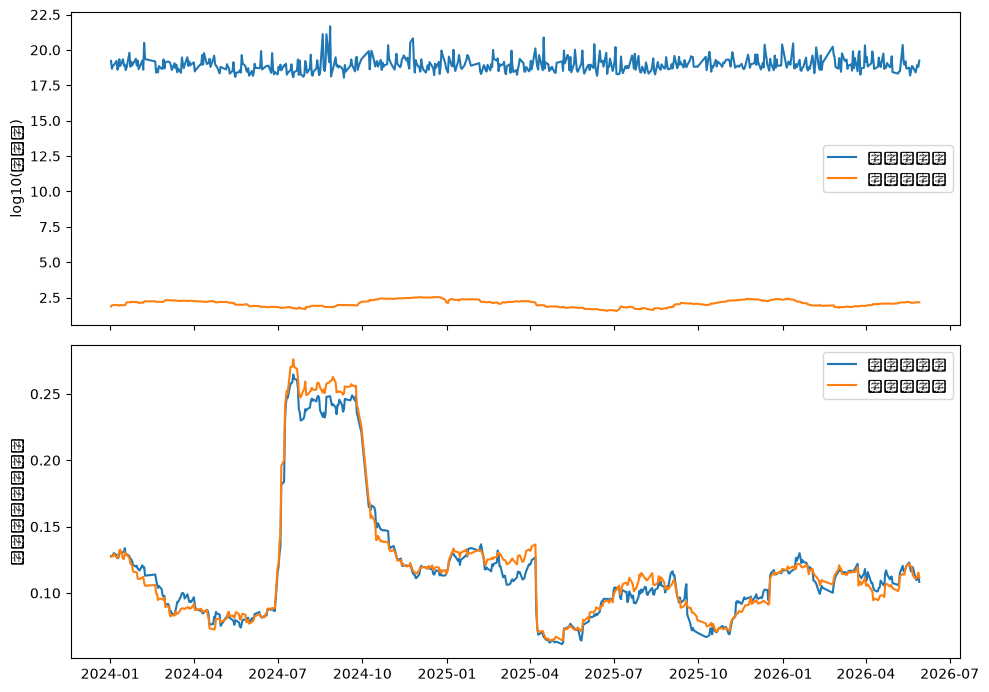

e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 26465 (\N{CJK UNIFIED IDEOGRAPH-6761}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
e:\miniconda3\envs\quant\Lib\site-packages\IPython\core\events.py

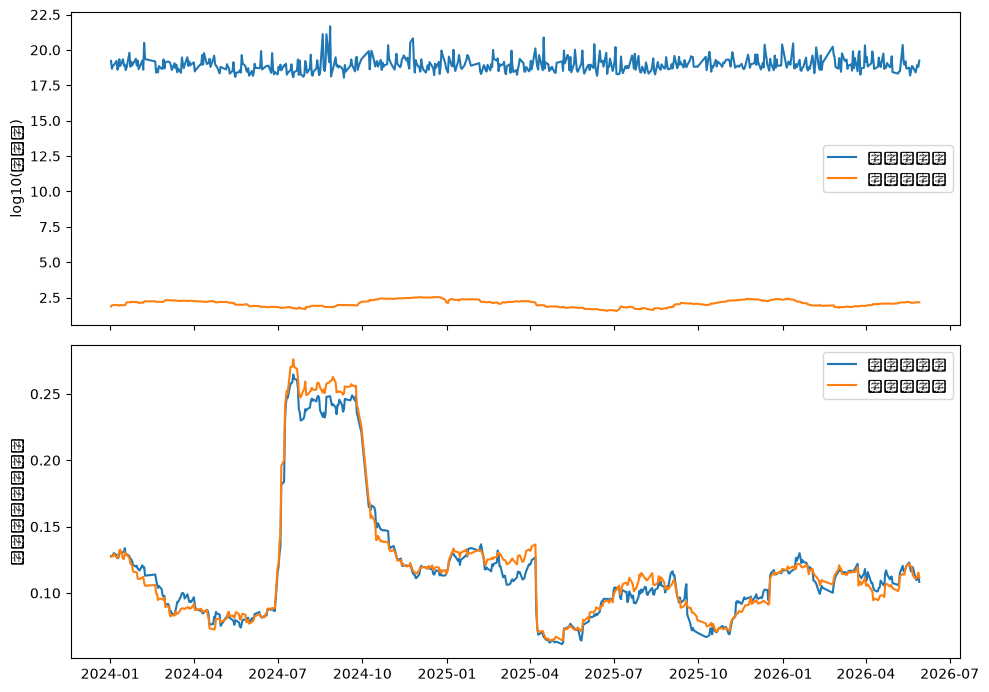

In [9]:
s = pd.read_csv("data/drill2_sample_cov_2024-01_2026-05.csv", index_col=0, parse_dates=True)
k = pd.read_csv("data/drill2_shrink_cov_2024-01_2026-05.csv", index_col=0, parse_dates=True)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(s.index, np.log10(s["cond"]), label="样本协方差")
axes[0].plot(k.index, np.log10(k["cond"]), label="收缩协方差")
axes[0].set_ylabel("log10(条件数)")
axes[0].legend()
axes[1].plot(s.index, s["vol"], label="样本协方差")
axes[1].plot(k.index, k["vol"], label="收缩协方差")
axes[1].set_ylabel("样本外年化波动率")
axes[1].legend()
fig.tight_layout()
fig.savefig("data/drill2_compare.png", dpi=150)
fig
